### Part 1: Analyzing Best-Seller Trends Across Product Categories

**Objective**: Understand the relationship between product categories and their best-seller status.

1. **Crosstab Analysis**:
    - Create a crosstab between the product `category` and the `isBestSeller` status.
    
    - Are there categories where being a best-seller is more prevalent? 
    	
    	*Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.*

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 6)
pd.set_option("display.max_columns", None)

In [2]:
amz_raw = pd.read_csv("../lab-eda-univariate/amz_uk_price_prediction_dataset.csv")


In [3]:
amz = amz_raw.copy()

In [ ]:
bestseller = pd.crosstab(
    amz["category"],
    amz["isBestSeller"],
    normalize="index"
)

bestseller = bestseller.sort_values(
    by= True,
    ascending=False
)

display((bestseller * 100).round(2))

# Grocery, Smart Home Security & Lighting, Health & Personal Care ar categories where best seller is more prevalent

isBestSeller,False,True
category,,
Grocery,94.19,5.81
Smart Home Security & Lighting,94.23,5.77
Health & Personal Care,94.23,5.77
Mobile Phone Accessories,95.75,4.25
Power & Hand Tools,96.47,3.53
...,...,...
Bedding Collections,100.00,0.00
CPUs,100.00,0.00
"CD, Disc & Tape Players",100.00,0.00


 **Statistical Tests**:
    - Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
    - Compute Cramér's V to understand the strength of association between best-seller status and category.

In [13]:
contingency_table = pd.crosstab(amz["category"], amz["isBestSeller"])

chi2, p_value, degrees_of_freedom, expected = stats.chi2_contingency(
    contingency_table
)

print(f"Chi-square statistic: {chi2:.2f}")
print(f"Degrees of freedom: {degrees_of_freedom}")
print(f"P-value: {p_value:.4g}")

Chi-square statistic: 36540.20
Degrees of freedom: 295
P-value: 0


In [17]:
from scipy.stats.contingency import association

table = pd.crosstab(amz["category"], amz["isBestSeller"])

rows = [{
    "relationship": "category vs. isBestSeller",
    "p_value": stats.chi2_contingency(table)[1],
    "cramers_v": association(table, method="cramer")
}]

pd.DataFrame(rows).round(4)

,relationship,p_value,cramers_v
0,category vs. isBestSeller,0.0,0.1223



3. **Visualizations**:
	- Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

---

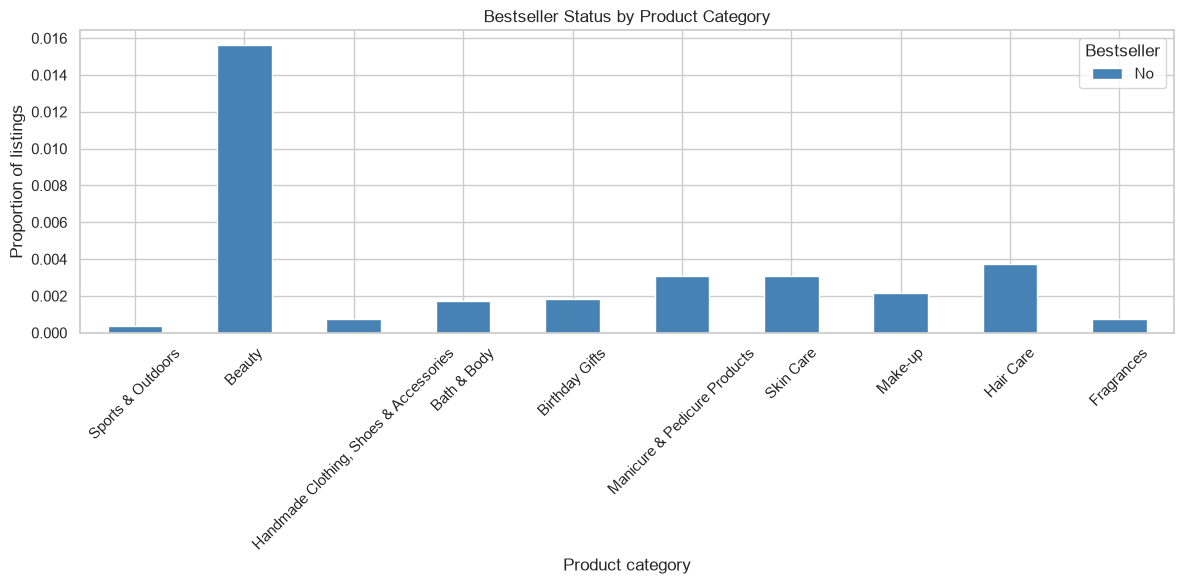

In [26]:
# 3. 100% stacked bar chart for the 10 most-listed categories
top10 = table.sum(axis=1).nlargest(10).index

ax = proportions.loc[top10, [False, True]].plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6),
    color=["steelblue", "orange"]
)

ax.set_title("Bestseller Status by Product Category")
ax.set_xlabel("Product category")
ax.set_ylabel("Proportion of listings")
ax.legend(title="Bestseller", labels=["No", "Yes"])
ax.tick_params(axis="x", labelrotation=45)

plt.tight_layout()
plt.show()

0. **Preliminary Step: Remove outliers in product prices.**

	For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.
	
	*Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.*

In [31]:
Q1 = amz["price"].quantile(0.25)
Q3 = amz["price"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

amz_no_outliers = amz[
    amz["price"].between(lower_bound, upper_bound)
].copy()

print(f"Price bounds: £{lower_bound:.2f} to £{upper_bound:.2f}")
print(f"Rows removed: {len(amz) - len(amz_no_outliers):,}")

Price bounds: £-44.01 to £99.99
Rows removed: 327,688


 **Violin Plots**:
    - Use a violin plot to visualize the distribution of `price` across different product `categories`. Filter out the top 20 categories based on count for better visualization.
    - Which product category tends to have the highest median price? Don't filter here by top categories.

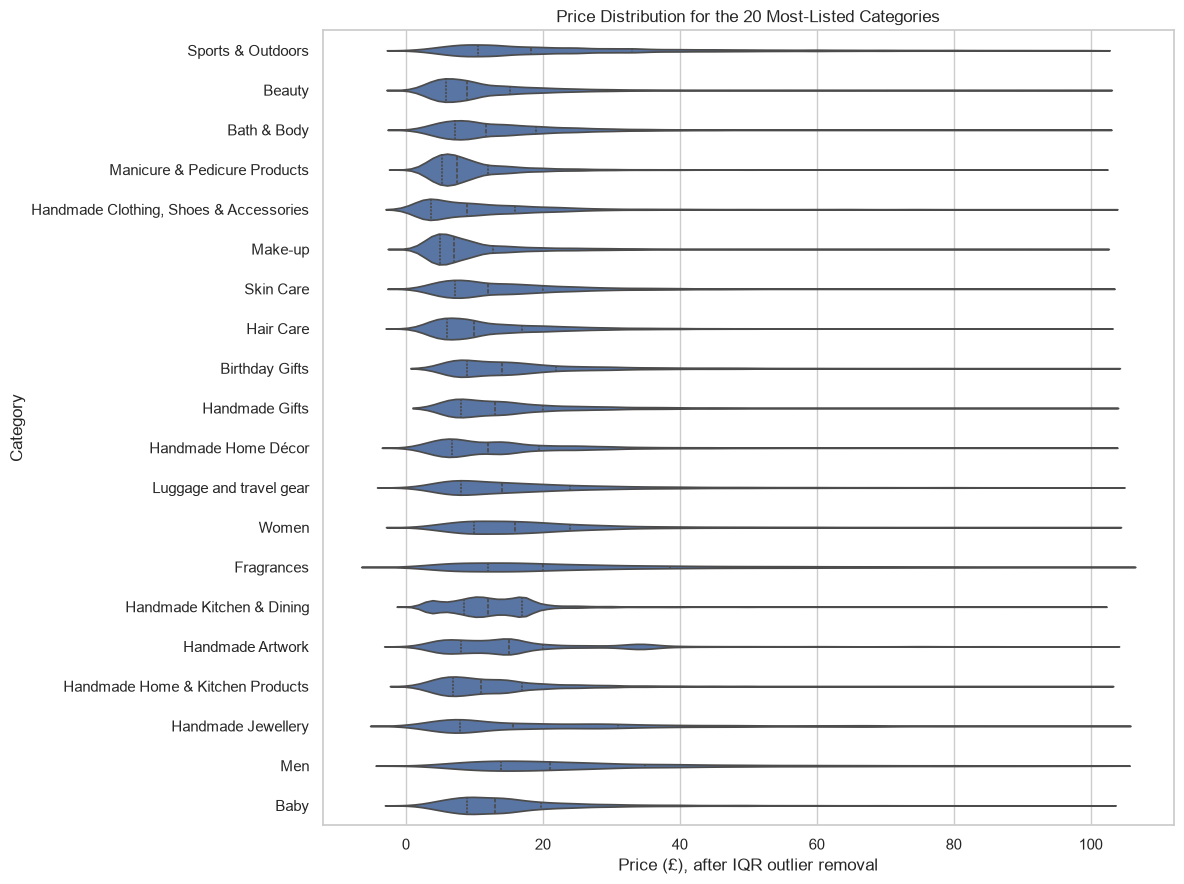

Highest median price: 74.0
category
Desktop PCs    74.0
Name: price, dtype: float64


In [33]:
# Top 20 categories by listing count in the filtered dataframe
top20 = amz_no_outliers["category"].value_counts().head(20).index
plot_data = amz_no_outliers[
    amz_no_outliers["category"].isin(top20)
]

plt.figure(figsize=(12, 9))
sns.violinplot(
    data=plot_data,
    x="price",
    y="category",
    order=top20,
    inner="quartile"
)
plt.title("Price Distribution for the 20 Most-Listed Categories")
plt.xlabel("Price (£), after IQR outlier removal")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

# Highest median price across all categories, not just the top 20
category_medians = amz_no_outliers.groupby("category")["price"].median()
print("Highest median price:", category_medians.max())
print(category_medians[category_medians == category_medians.max()])


2. **Bar Charts**:
    - Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
    - Which product category commands the highest average price? Don't filter here by top categories.

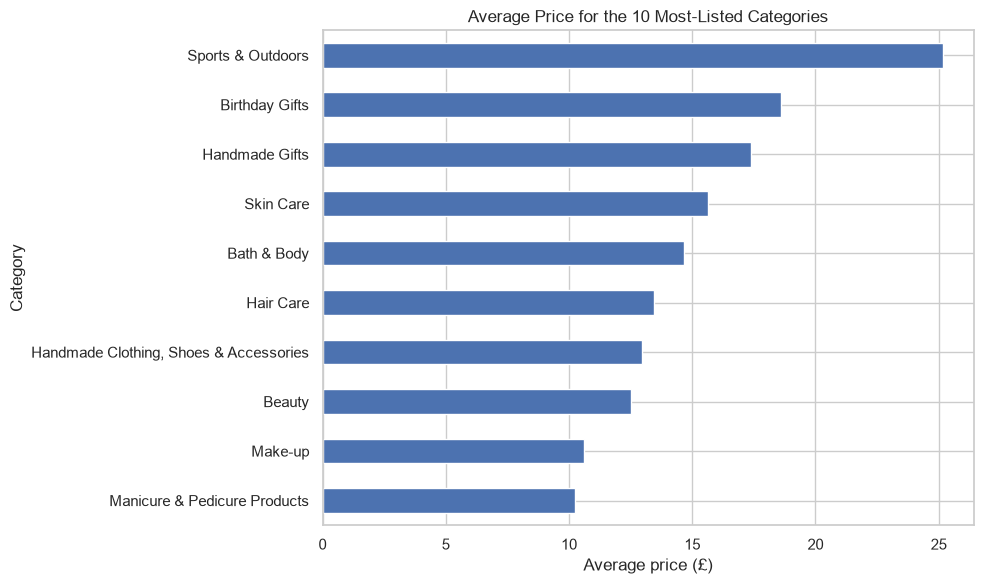

In [36]:
top10_categories = amz_no_outliers["category"].value_counts().head(10).index

avg_price_top10 = (
    amz_no_outliers[amz_no_outliers["category"].isin(top10_categories)]
    .groupby("category")["price"]
    .mean()
    .sort_values()
)

avg_price_top10.plot(kind="barh", figsize=(10, 6))
plt.title("Average Price for the 10 Most-Listed Categories")
plt.xlabel("Average price (£)")
plt.ylabel("Category")
plt.tight_layout()
plt.show()


3. **Box Plots**:
    - Visualize the distribution of product `ratings` based on their `category` using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
    - Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

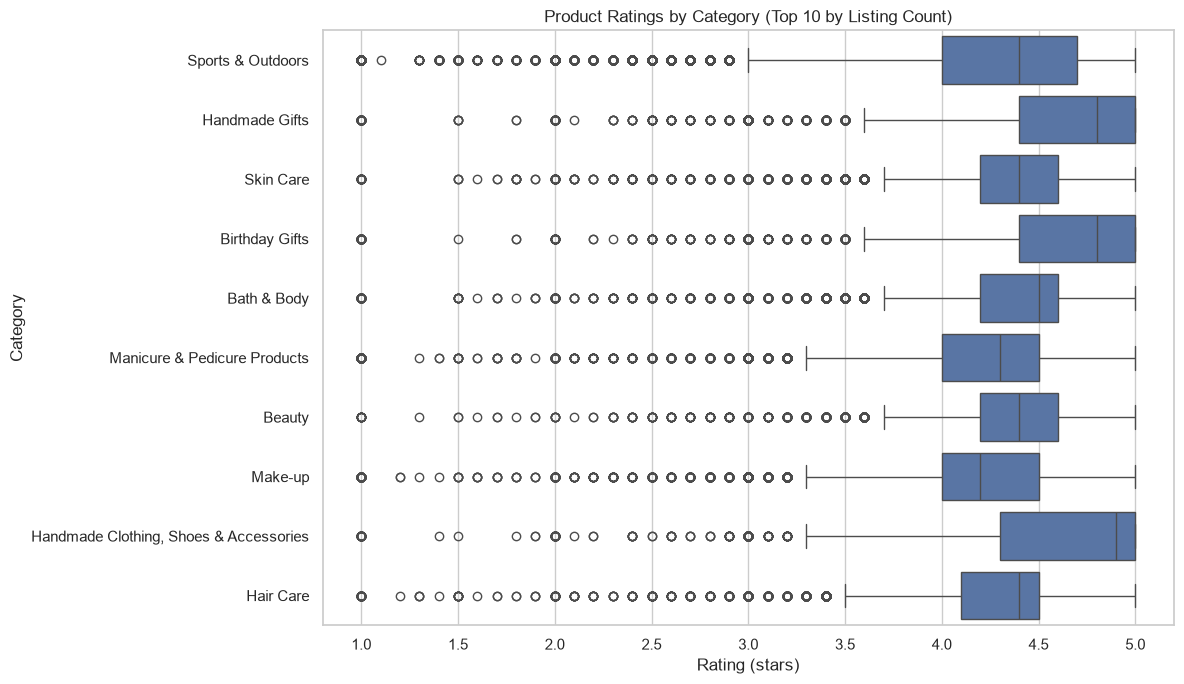

category
Handmade Artwork          5.0
Handmade Baby Products    5.0
Made in Italy Handmade    5.0
Name: stars, dtype: float64


In [41]:
# Exclude zero ratings if they indicate unrated products
rated = amz_no_outliers[amz_no_outliers["stars"] > 0]

# Plot only the 10 most-listed categories
top10 = amz_no_outliers["category"].value_counts().head(10).index
plot_data = rated[rated["category"].isin(top10)]

plt.figure(figsize=(12, 7))
sns.boxplot(data=plot_data, x="stars", y="category")
plt.title("Product Ratings by Category (Top 10 by Listing Count)")
plt.xlabel("Rating (stars)")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

# Find the highest median across all categories
medians = rated.groupby("category")["stars"].median()
print(medians[medians == medians.max()])

### Part 3: Investigating the Interplay Between Product Prices and Ratings

**Objective**: Analyze how product ratings (`stars`) correlate with product prices.

1. **Correlation Coefficients**:
    - Calculate the correlation coefficient between `price` and `stars`.
    - Is there a significant correlation between product price and its rating?

In [43]:
rated_prices = amz_no_outliers.loc[
    amz_no_outliers["stars"] > 0,
    ["price", "stars"]
].dropna()

r, p_value = stats.pearsonr(
    rated_prices["price"],
    rated_prices["stars"]
)

print(f"Pearson correlation: {r:.4f}")
print(f"P-value: {p_value:.4g}")

Pearson correlation: 0.0067
P-value: 1.081e-12


In [44]:
#With this dataset, r ≈ 0.0067: the relationship is positive but extremely weak—practically, price and rating are almost uncorrelated. The p-value is below 0.05, so it is statistically significant, likely because the dataset has over a million rated products. Statistical significance here does not mean the relationship is strong or useful in practice.



	
2. **Visualizations**:
    - Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
    - Use a correlation heatmap to visualize correlations between all numerical variables.
    - Examine if product prices typically follow a normal distribution using a QQ plot. 

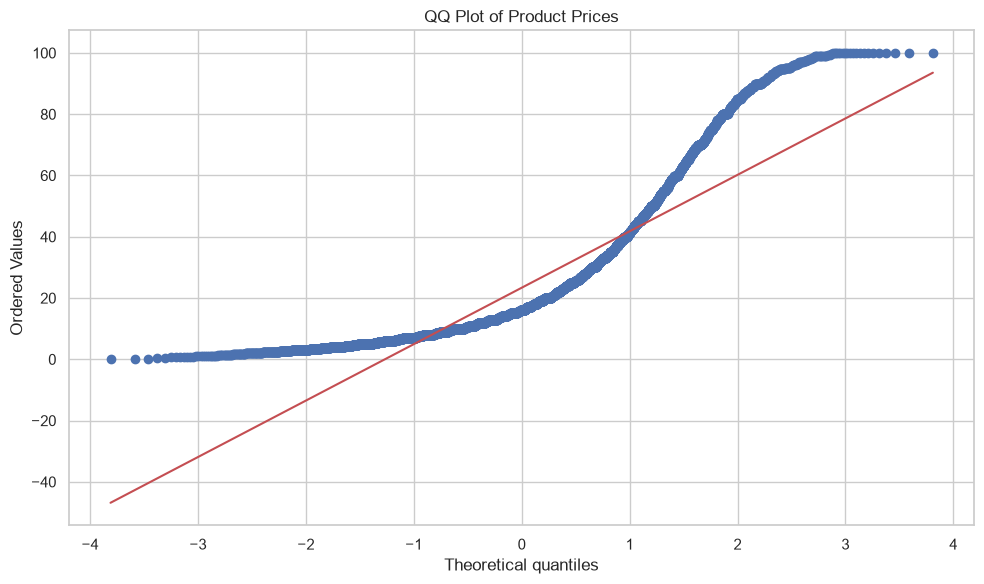

In [45]:
price_sample = amz_no_outliers["price"].sample(
    n=min(10_000, len(amz_no_outliers)),
    random_state=42
)

stats.probplot(price_sample, dist="norm", plot=plt)
plt.title("QQ Plot of Product Prices")
plt.tight_layout()
plt.show()

In [46]:
#If the prices were normally distributed, the points would roughly follow the straight reference line. Prices typically deviate from that line, especially in the upper tail, indicating that the distribution is not normal and remains right-skewed even after IQR outlier removal.
